# PaleographIA · Comparação de reconhecedores na carta de 1767

**Projeto Integrador IV e Processamento de Linguagem Natural**  
Continuação do Notebook 1 · avaliação executada em 4 de novembro de 2026

**Pergunta.** Como PP-OCRv5 mobile e PP-OCRv6 medium se comportam nas mesmas três linhas de um manuscrito histórico, usando como referência a transcrição diplomática conferida por um revisor?

A comparação usa as linhas **1, 3 e 4** da anotação superior do fólio **4r** da carta de José Gomes de Gouveia. Os dois reconhecedores recebem os mesmos PNGs, na mesma ordem, com seus pré-processamentos nativos. O escopo é reconhecimento em recortes fixos de um documento de desenvolvimento.

**Como apresentar.** Execute todas as células no Colab ou no Jupyter para recalcular as métricas e comparar imagens, referências e previsões. Os dados estão incorporados. A célula de inferência permite rodar ambos os reconhecedores ao vivo em um checkout local preparado, com a `.venv`, os pesos e o Docker. A seção final documenta o ajuste fino técnico já executado e o que falta para o experimento com teste reservado.

In [1]:
# @title 1. Carregar os dados da execução arquivada
import base64
import hashlib
import json
from html import escape
from IPython.display import HTML, Image, display

def ler_jsonl(texto):
    return [json.loads(linha) for linha in texto.splitlines() if linha.strip()]

def tabela(titulos, linhas):
    cabecalho = ''.join(f'<th scope="col">{escape(str(t))}</th>' for t in titulos)
    corpo = ''.join('<tr>' + ''.join(f'<td>{escape(str(v))}</td>' for v in linha) + '</tr>' for linha in linhas)
    display(HTML(f'<table><thead><tr>{cabecalho}</tr></thead><tbody>{corpo}</tbody></table>'))

ARQUIVOS = {'referencias': '{"line_id": "l_14a4c7eba267e1e592e7", "page_id": "p_c02_7b71d03c0d1bf8c7", "document_id": "carta_jose_gomes_1767", "folio_id": "4r", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 0, "source_image": "data/raw/corpus_expandido_v02/fontes/carta_jose_gomes_1767/manuscript_image_7d9c6e3e9a0728b1.jpg", "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_14a4c7eba267e1e592e7.png", "bbox_xyxy": [40, 8, 775, 107], "source_width": 1237, "source_height": 1807, "text_diplomatic": "Paguem as Camaras, e a Razão por não", "text_modernized": "Paguem as Câmaras, e a razão por que não", "reference_source": "data/raw/corpus_expandido_v02/fontes/carta_jose_gomes_1767/modernized_edition_500a24d6a2ea8b93.pdf", "reference_pages": [3], "reference_kind": "human_diplomatic", "review_status": "validated", "reviewer": "Rodolfo Vinicius Cima Takemoto", "reviewed_at": "2026-11-04T15:27:43.1097086Z", "text_review_observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_079_linha01_transcricao_diplomatica_validada.json", "geometry_status": "validated", "geometry_review_observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_068_linha01_recorte_definitivo_aprovado.json", "split": null, "split_group": "carta_jose_gomes_1767", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "transform_id": "81e8eb9a42bbbbd87fdd3e8a171d4436e17541522e51735c13f571b4dbc5f8da", "exclusion_reason": null, "derived_from": null, "segmentation_method": "manual_candidate_not_human_approved", "crop_sha256": "44cfce738bc01e09f6585232e754c5100984628d932423cf7d98cb8bb3b137de"}\n{"line_id": "l_5e33f0d507567e36dd02", "page_id": "p_c02_7b71d03c0d1bf8c7", "document_id": "carta_jose_gomes_1767", "folio_id": "4r", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 2, "source_image": "data/raw/corpus_expandido_v02/fontes/carta_jose_gomes_1767/manuscript_image_7d9c6e3e9a0728b1.jpg", "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_5e33f0d507567e36dd02.png", "bbox_xyxy": [43, 115, 802, 227], "source_width": 1237, "source_height": 1807, "text_diplomatic": "se as não tivessem seriam Srsˢ dos Desco-", "text_modernized": "se as não tivessem seriam senhores dos Desco", "reference_source": "data/raw/corpus_expandido_v02/fontes/carta_jose_gomes_1767/modernized_edition_500a24d6a2ea8b93.pdf", "reference_pages": [3], "reference_kind": "human_diplomatic", "review_status": "validated", "reviewer": "Rodolfo Vinicius Cima Takemoto", "reviewed_at": "2026-11-04T16:08:39.7425515Z", "text_review_observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_086_linha03_transcricao_diplomatica_validada.json", "geometry_status": "validated", "geometry_review_observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_073_linha03_recorte_definitivo_aprovado.json", "split": null, "split_group": "carta_jose_gomes_1767", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "transform_id": "25d97e3ffd39afcc1e3a88ed401238c5748e4a5919791617916627fc9dc659e0", "exclusion_reason": null, "derived_from": null, "segmentation_method": "manual_candidate_not_human_approved", "crop_sha256": "243963b72f2591d706d5e3fc923cbd88938f2d9147d594ac1359fd5c7e95f185"}\n{"line_id": "l_99b58f3e657c7885a0de", "page_id": "p_c02_7b71d03c0d1bf8c7", "document_id": "carta_jose_gomes_1767", "folio_id": "4r", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 3, "source_image": "data/raw/corpus_expandido_v02/fontes/carta_jose_gomes_1767/manuscript_image_7d9c6e3e9a0728b1.jpg", "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_99b58f3e657c7885a0de.png", "bbox_xyxy": [43, 177, 877, 293], "source_width": 1237, "source_height": 1807, "text_diplomatic": "bertos do campo verde, e de outros muⁱᵗᵒˢ que estão", "text_modernized": "bertos do Campo verde, e de outros muitos que estão", "reference_source": "data/raw/corpus_expandido_v02/fontes/carta_jose_gomes_1767/modernized_edition_500a24d6a2ea8b93.pdf", "reference_pages": [3], "reference_kind": "human_diplomatic", "review_status": "validated", "reviewer": "Rodolfo Vinicius Cima Takemoto", "reviewed_at": "2026-11-04T16:51:44.5611745Z", "text_review_observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_091_linha04_transcricao_diplomatica_validada.json", "geometry_status": "validated", "geometry_review_observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_075_linha04_recorte_definitivo_aprovado.json", "split": null, "split_group": "carta_jose_gomes_1767", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "transform_id": "91ab8c246a65aeba8b252295ec64b3d63e702fdcf8afb49c55ca3d37e1fc6b7b", "exclusion_reason": null, "derived_from": null, "segmentation_method": "manual_candidate_not_human_approved", "crop_sha256": "99a1b84e23edb915aa9e1e0f2549011e7c023631c10bc388f878379f02085c7d"}\n', 'exclusoes': '{"line": 2, "line_id": "l_90945ed471090b684539", "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_90945ed471090b684539.png", "crop_sha256": "0d24c40fd890d81de8f39aa6dcf0283612187ddc5021d65ae84cee21b58e9ba8", "geometry_status": "validated", "review_status": "pending_review", "reason": "Forma manuscrita após tem pendente; dinheiro fica na leitura de apoio.", "observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_082_linha02_que_final_por_extenso.json"}\n{"line": 5, "line_id": "l_119f8864ca552d4d0f7d", "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_119f8864ca552d4d0f7d.png", "crop_sha256": "edad9c5933f9621b0c407f30710de941ff7b92e540c7780c49f0ccfc4414b431", "geometry_status": "validated", "review_status": "pending_review", "reason": "Forma literal antes de Paulo pendente; São Paulo adotado da edição para a leitura assistida.", "observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_095_linha05_sao_paulo_adotado_da_edicao.json"}\n{"line": 6, "line_id": "l_5ae79db91a78f1a9aada", "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_5ae79db91a78f1a9aada.png", "crop_sha256": "62039aa7001c7bda8087fa432213a487ffc0dca6d563f7f13a1b5ff1ec97aa82", "geometry_status": "validated", "review_status": "pending_review", "reason": "Forma literal abreviada do mês pendente; dezembro fica na leitura de apoio.", "observation": "docs/revisao_humana/carta_jose_gomes_1767/sessao_20261103/observacao_098_linha06_sem_ponto_separado_apos_1767.json"}\n', 'ppocrv5': '{"line_id": "l_14a4c7eba267e1e592e7", "page_id": "p_c02_7b71d03c0d1bf8c7", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 0, "bbox_xyxy": [40, 8, 775, 107], "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_14a4c7eba267e1e592e7.png", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "execution_id": "20261104T173918_3f4b45e5", "text_raw": "Cayuem n Camen ealia pognas.", "token_ids": [0, 35, 65, 89, 89, 85, 69, 77, 77, 503, 503, 0, 78, 503, 35, 65, 0, 77, 69, 0, 78, 0, 503, 69, 65, 76, 76, 0, 73, 65, 0, 503, 80, 79, 0, 71, 0, 78, 0, 65, 0, 83, 0, 14], "model": {"id": "PaddlePaddle/latin_PP-OCRv5_mobile_rec", "conversion": "RapidAI/RapidOCR ONNX", "registry_revision": "7cfd3d9ef786a2e538ca30df700325e72e85b5f5", "url": "https://www.modelscope.cn/models/RapidAI/RapidOCR/resolve/v3.10.0/onnx/PP-OCRv5/rec/latin_PP-OCRv5_rec_mobile.onnx", "sha256": "b20bd37c168a570f583afbc8cd7925603890efbcdc000a59e22c269d160b5f5a", "dictionary_sha256": "3c0a8a79b612653c25f765271714f71281e4e955962c153e272b7b8c1d2b13ff", "dictionary_classes_with_blank_space": 504, "fallback": false, "onnxruntime": "1.23.2", "providers": ["CPUExecutionProvider"], "threads": 1, "execution_mode": "ORT_SEQUENTIAL"}, "device": "cpu", "precision": "float32", "possible_truncation": false, "generation_limit_reached": false, "decoding": "greedy_ctc_blank_0", "preprocessing": {"color": "BGR", "height": 48, "min_width": 320, "resize": "cv2.INTER_LINEAR; preserve aspect ratio; right zero padding", "normalization": "(pixel/255 - 0.5)/0.5", "input_shape": [1, 3, 48, 356]}, "recognition_seconds": 0.060688300000038, "created_at": "2026-11-04T17:39:19.174443+00:00", "status": "ok"}\n{"line_id": "l_5e33f0d507567e36dd02", "page_id": "p_c02_7b71d03c0d1bf8c7", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 2, "bbox_xyxy": [43, 115, 802, 227], "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_5e33f0d507567e36dd02.png", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "execution_id": "20261104T173918_3f4b45e5", "text_raw": "n lmn r.do Ee", "token_ids": [0, 0, 0, 0, 78, 0, 0, 0, 503, 0, 0, 0, 76, 0, 77, 0, 0, 0, 0, 78, 0, 0, 503, 0, 0, 0, 82, 14, 68, 68, 79, 0, 503, 37, 0, 0, 0, 0, 69, 0, 0], "model": {"id": "PaddlePaddle/latin_PP-OCRv5_mobile_rec", "conversion": "RapidAI/RapidOCR ONNX", "registry_revision": "7cfd3d9ef786a2e538ca30df700325e72e85b5f5", "url": "https://www.modelscope.cn/models/RapidAI/RapidOCR/resolve/v3.10.0/onnx/PP-OCRv5/rec/latin_PP-OCRv5_rec_mobile.onnx", "sha256": "b20bd37c168a570f583afbc8cd7925603890efbcdc000a59e22c269d160b5f5a", "dictionary_sha256": "3c0a8a79b612653c25f765271714f71281e4e955962c153e272b7b8c1d2b13ff", "dictionary_classes_with_blank_space": 504, "fallback": false, "onnxruntime": "1.23.2", "providers": ["CPUExecutionProvider"], "threads": 1, "execution_mode": "ORT_SEQUENTIAL"}, "device": "cpu", "precision": "float32", "possible_truncation": false, "generation_limit_reached": false, "decoding": "greedy_ctc_blank_0", "preprocessing": {"color": "BGR", "height": 48, "min_width": 320, "resize": "cv2.INTER_LINEAR; preserve aspect ratio; right zero padding", "normalization": "(pixel/255 - 0.5)/0.5", "input_shape": [1, 3, 48, 325]}, "recognition_seconds": 0.044545100012328476, "created_at": "2026-11-04T17:39:19.220385+00:00", "status": "ok"}\n{"line_id": "l_99b58f3e657c7885a0de", "page_id": "p_c02_7b71d03c0d1bf8c7", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 3, "bbox_xyxy": [43, 177, 877, 293], "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_99b58f3e657c7885a0de.png", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "execution_id": "20261104T173918_3f4b45e5", "text_raw": "d", "token_ids": [0, 0, 0, 0, 0, 68, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], "model": {"id": "PaddlePaddle/latin_PP-OCRv5_mobile_rec", "conversion": "RapidAI/RapidOCR ONNX", "registry_revision": "7cfd3d9ef786a2e538ca30df700325e72e85b5f5", "url": "https://www.modelscope.cn/models/RapidAI/RapidOCR/resolve/v3.10.0/onnx/PP-OCRv5/rec/latin_PP-OCRv5_rec_mobile.onnx", "sha256": "b20bd37c168a570f583afbc8cd7925603890efbcdc000a59e22c269d160b5f5a", "dictionary_sha256": "3c0a8a79b612653c25f765271714f71281e4e955962c153e272b7b8c1d2b13ff", "dictionary_classes_with_blank_space": 504, "fallback": false, "onnxruntime": "1.23.2", "providers": ["CPUExecutionProvider"], "threads": 1, "execution_mode": "ORT_SEQUENTIAL"}, "device": "cpu", "precision": "float32", "possible_truncation": false, "generation_limit_reached": false, "decoding": "greedy_ctc_blank_0", "preprocessing": {"color": "BGR", "height": 48, "min_width": 320, "resize": "cv2.INTER_LINEAR; preserve aspect ratio; right zero padding", "normalization": "(pixel/255 - 0.5)/0.5", "input_shape": [1, 3, 48, 345]}, "recognition_seconds": 0.048899599991273135, "created_at": "2026-11-04T17:39:19.269967+00:00", "status": "ok"}\n', 'ppocrv6': '{"line_id": "l_14a4c7eba267e1e592e7", "page_id": "p_c02_7b71d03c0d1bf8c7", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 0, "bbox_xyxy": [40, 8, 775, 107], "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_14a4c7eba267e1e592e7.png", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "execution_id": "20261104T173920_730c422e", "text_raw": "Paquem as Camaras, e alazaõ porq̄ nao", "token_ids": [0, 0, 0, 0, 0, 49, 0, 66, 0, 82, 0, 86, 0, 0, 70, 0, 78, 0, 0, 0, 1, 1, 0, 66, 0, 84, 0, 1, 1, 36, 0, 0, 66, 0, 0, 78, 0, 0, 0, 66, 0, 83, 0, 66, 84, 0, 13, 1, 70, 1, 1, 66, 0, 77, 0, 66, 0, 91, 0, 66, 0, 0, 80, 212, 1, 81, 0, 0, 80, 83, 83, 0, 82, 213, 1, 1, 79, 0, 0, 0, 66, 0, 80, 80, 0, 0, 0, 0, 0, 0, 0, 0, 0], "recognition_seconds": 1.0086024999999985, "preprocessing": {"input_size": [735, 99], "pixel_sha256": "40776e040e0f9bda07e413e66201d704930e1cdccbf6d5d4e25d1a4c6a7eb209", "tensor_shape": [1, 3, 96, 744], "line_height": 96, "horizontal_padding": 16, "valid_norm": false, "line_detection": false, "polygon_extraction": false, "transform": "Kraken 7.1 ImageInputTransforms (baseline line convention)"}, "model": {"id": "zenodo:21788410/medium.safetensors", "sha256": "15313b51ace64cbfa81f8f6ef25ad64f04e5a6fb7f7823e67b107527bc081ac9", "backend": "kraken_ppocrv6", "architecture": "PPOCRv6Model", "variant": "medium", "model_input": [1, 3, 96, 0], "seg_type": "baselines", "runtime": {"kraken": "7.1", "torch": "2.9.1+cpu", "torchvision": "0.24.1+cpu", "numpy": "2.4.6", "Pillow": "12.3.0", "safetensors": "0.7.0", "lightning": "2.6.1"}, "python": "3.12.15", "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.41", "fallback": false, "docker_image_id": "sha256:511fb2e2b76db8de0d3eb87dcf04398f7a02fc06b5d91887629b2492f826af5b", "worker_sha256": "825d6bea5171187c9f6dfa310f1fd0a9cc8fe933e9f72417f3ea43a0c628029a"}, "device": "cpu", "precision": "float32", "possible_truncation": false, "generation_limit_reached": false, "seed": 1831, "created_at": "2026-11-04T17:39:46.191061+00:00", "decoding": "Kraken greedy CTC; no correction", "status": "ok"}\n{"line_id": "l_5e33f0d507567e36dd02", "page_id": "p_c02_7b71d03c0d1bf8c7", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 2, "bbox_xyxy": [43, 115, 802, 227], "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_5e33f0d507567e36dd02.png", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "execution_id": "20261104T173920_730c422e", "text_raw": "cas nad tivessem Seriaõ Snr. dos Deseu", "token_ids": [0, 0, 0, 0, 68, 0, 66, 0, 84, 1, 1, 79, 0, 66, 0, 69, 0, 1, 85, 74, 0, 87, 0, 70, 84, 0, 84, 70, 78, 78, 0, 0, 0, 1, 1, 52, 0, 70, 0, 83, 74, 0, 66, 0, 80, 212, 0, 1, 0, 52, 0, 79, 0, 83, 83, 15, 0, 0, 1, 1, 69, 80, 80, 84, 84, 1, 1, 37, 0, 70, 0, 84, 70, 0, 86, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], "recognition_seconds": 0.808678699999998, "preprocessing": {"input_size": [759, 112], "pixel_sha256": "4e0ea66e9be754474705157505ccf9bb4b1f42cb022f6a27e08d26e5a92dc563", "tensor_shape": [1, 3, 96, 682], "line_height": 96, "horizontal_padding": 16, "valid_norm": false, "line_detection": false, "polygon_extraction": false, "transform": "Kraken 7.1 ImageInputTransforms (baseline line convention)"}, "model": {"id": "zenodo:21788410/medium.safetensors", "sha256": "15313b51ace64cbfa81f8f6ef25ad64f04e5a6fb7f7823e67b107527bc081ac9", "backend": "kraken_ppocrv6", "architecture": "PPOCRv6Model", "variant": "medium", "model_input": [1, 3, 96, 0], "seg_type": "baselines", "runtime": {"kraken": "7.1", "torch": "2.9.1+cpu", "torchvision": "0.24.1+cpu", "numpy": "2.4.6", "Pillow": "12.3.0", "safetensors": "0.7.0", "lightning": "2.6.1"}, "python": "3.12.15", "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.41", "fallback": false, "docker_image_id": "sha256:511fb2e2b76db8de0d3eb87dcf04398f7a02fc06b5d91887629b2492f826af5b", "worker_sha256": "825d6bea5171187c9f6dfa310f1fd0a9cc8fe933e9f72417f3ea43a0c628029a"}, "device": "cpu", "precision": "float32", "possible_truncation": false, "generation_limit_reached": false, "seed": 1831, "created_at": "2026-11-04T17:39:47.096506+00:00", "decoding": "Kraken greedy CTC; no correction", "status": "ok"}\n{"line_id": "l_99b58f3e657c7885a0de", "page_id": "p_c02_7b71d03c0d1bf8c7", "region_id": "anotacao_superior_esquerda_seis_linhas", "reading_order": 3, "bbox_xyxy": [43, 177, 877, 293], "crop_image": "docs/revisao_humana/carta_jose_gomes_1767/preparacao_20261103/l_99b58f3e657c7885a0de.png", "source_sha256": "7d9c6e3e9a0728b155d6a6d390b5e70622e7724ac1bbe527e1cebd89ab45f546", "execution_id": "20261104T173920_730c422e", "text_raw": "ntos do lampo vorde, e de Outros m.tos que estao", "token_ids": [0, 0, 0, 79, 0, 85, 0, 80, 84, 0, 1, 0, 69, 80, 1, 1, 77, 66, 0, 78, 0, 0, 81, 0, 0, 80, 1, 1, 87, 0, 0, 80, 83, 83, 69, 69, 70, 0, 13, 1, 1, 70, 1, 69, 70, 1, 1, 48, 0, 86, 0, 0, 85, 83, 83, 80, 84, 1, 1, 78, 0, 0, 15, 15, 85, 80, 84, 1, 82, 82, 86, 0, 70, 70, 70, 1, 70, 0, 84, 0, 85, 0, 66, 0, 80, 0, 0, 0, 0, 0], "recognition_seconds": 1.109252099999999, "preprocessing": {"input_size": [834, 116], "pixel_sha256": "65719f55c981ec1365ae41173f4d5115d60e3c27b0023f25915351335425066c", "tensor_shape": [1, 3, 96, 722], "line_height": 96, "horizontal_padding": 16, "valid_norm": false, "line_detection": false, "polygon_extraction": false, "transform": "Kraken 7.1 ImageInputTransforms (baseline line convention)"}, "model": {"id": "zenodo:21788410/medium.safetensors", "sha256": "15313b51ace64cbfa81f8f6ef25ad64f04e5a6fb7f7823e67b107527bc081ac9", "backend": "kraken_ppocrv6", "architecture": "PPOCRv6Model", "variant": "medium", "model_input": [1, 3, 96, 0], "seg_type": "baselines", "runtime": {"kraken": "7.1", "torch": "2.9.1+cpu", "torchvision": "0.24.1+cpu", "numpy": "2.4.6", "Pillow": "12.3.0", "safetensors": "0.7.0", "lightning": "2.6.1"}, "python": "3.12.15", "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.41", "fallback": false, "docker_image_id": "sha256:511fb2e2b76db8de0d3eb87dcf04398f7a02fc06b5d91887629b2492f826af5b", "worker_sha256": "825d6bea5171187c9f6dfa310f1fd0a9cc8fe933e9f72417f3ea43a0c628029a"}, "device": "cpu", "precision": "float32", "possible_truncation": false, "generation_limit_reached": false, "seed": 1831, "created_at": "2026-11-04T17:39:48.313893+00:00", "decoding": "Kraken greedy CTC; no correction", "status": "ok"}\n'}
RECORTES_BASE64 = {'l_14a4c7eba267e1e592e7': '...', 'l_5e33f0d507567e36dd02': '...', 'l_99b58f3e657c7885a0de': '...'}
SHA256_REFERENCIAS = 'd6e2424a314f071c26ef65264f0540131f2bceec5737d5de8e9072c84919e992'
SHA256_PREDICOES = {'ppocrv5': '6a4fc5f611880eff82dca5737737dc3235033d7eb8b1b0e7adb324d8f6b06578', 'ppocrv6': '86ea78ff8cc8fe0e7cebcb843d716d4e2890c4be0c3b2b9e5e5436e9cf8cf233'}
METRICAS_ARQUIVADAS = {'ppocrv5': {'characters': {'substitutions': 16, 'deletions': 86, 'insertions': 0, 'hits': 26, 'reference_length': 128, 'errors': 102, 'rate': 0.796875}, 'words': {'substitutions': 10, 'deletions': 16, 'insertions': 0, 'hits': 0, 'reference_length': 26, 'errors': 26, 'rate': 1.0}}, 'ppocrv6': {'characters': {'substitutions': 22, 'deletions': 8, 'insertions': 3, 'hits': 98, 'reference_length': 128, 'errors': 33, 'rate': 0.2578125}, 'words': {'substitutions': 15, 'deletions': 2, 'insertions': 0, 'hits': 9, 'reference_length': 26, 'errors': 17, 'rate': 0.6538461538461539}}}

MODELOS = {'ppocrv5': 'PP-OCRv5 mobile / ONNX', 'ppocrv6': 'PP-OCRv6 medium / Kraken 7.1'}
REFERENCIAS = ler_jsonl(ARQUIVOS['referencias'])
EXCLUSOES = ler_jsonl(ARQUIVOS['exclusoes'])
assert hashlib.sha256(ARQUIVOS['referencias'].encode()).hexdigest() == SHA256_REFERENCIAS
for modelo, digest in SHA256_PREDICOES.items():
    assert hashlib.sha256(ARQUIVOS[modelo].encode()).hexdigest() == digest
for ref in REFERENCIAS:
    pixels = base64.b64decode(RECORTES_BASE64[ref['line_id']])
    assert hashlib.sha256(pixels).hexdigest() == ref['crop_sha256']
tabela(['Linha avaliada', 'Referência diplomática'], [(r['reading_order'] + 1, r['text_diplomatic']) for r in REFERENCIAS])
tabela(['Linha excluída', 'Motivo'], [(r['line'], r['reason']) for r in EXCLUSOES])

Linha avaliada,Referência diplomática
1,"Paguem as Camaras, e a Razão por não"
3,se as não tivessem seriam Srsˢ dos Desco-
4,"bertos do campo verde, e de outros muⁱᵗᵒˢ que estão"


Linha excluída,Motivo
2,Forma manuscrita após tem pendente; dinheiro fica na leitura de apoio.
5,Forma literal antes de Paulo pendente; São Paulo adotado da edição para a leitura assistida.
6,Forma literal abreviada do mês pendente; dezembro fica na leitura de apoio.


## Inferência ao vivo e reprodução dos resultados

A execução padrão usa as previsões brutas arquivadas em 04/11. Para ver o teste ao vivo, abra o notebook no **Jupyter local**, com a pasta do projeto acessível, e mude `EXECUTAR_INFERENCIA_LOCAL` para `True`. A célula chama os dois reconhecedores do repositório e registra a nova execução em uma pasta própria. O Colab permite executar o recálculo; a configuração Kraken desta demonstração exige o Docker local do projeto.

In [2]:
# @title 2. Selecionar previsões arquivadas ou executar os modelos localmente
from datetime import datetime, timezone
import os
from pathlib import Path
import subprocess
import sys

EXECUTAR_INFERENCIA_LOCAL = False
ao_vivo = EXECUTAR_INFERENCIA_LOCAL or os.getenv('PALEOGRAPHIA_DEMO_LOCAL') == '1'
if ao_vivo:
    caminho_pacote = Path('docs/entregas/continuidade_20261103/avaliacao_linhas_1767')
    raiz = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / caminho_pacote / 'avaliar.py').is_file()), None)
    if raiz is None:
        raise RuntimeError('Abra o Jupyter a partir do checkout do PaleographIA para executar os reconhecedores.')
    python_venv = raiz / ('.venv/Scripts/python.exe' if os.name == 'nt' else '.venv/bin/python')
    python = str(python_venv) if python_venv.is_file() else sys.executable
    sufixo = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%f')
    destino = Path('output/avaliacao_linhas_1767') / f'demo_notebook_{sufixo}'
    manifest = (caminho_pacote / 'recortes.jsonl').as_posix()
    script = (caminho_pacote / 'avaliar.py').as_posix()
    v5, v6 = ((destino / modelo / 'predictions.jsonl').as_posix() for modelo in MODELOS)
    comandos = [
        [script],
        ['scripts/recognize_latin.py', '--lines', manifest, '--output', v5],
        ['-m', 'paleographia', 'recognize', '--config', 'configs/traslado_269r.toml', '--lines', manifest, '--output', v6],
        [script, '--ppocrv5', v5, '--ppocrv6', v6, '--output-dir', (destino / 'metricas').as_posix()],
    ]
    for comando in comandos:
        processo = subprocess.run([python, '-X', 'utf8', *comando], cwd=raiz, capture_output=True, encoding='utf-8')
        if processo.returncode:
            raise RuntimeError((processo.stderr or processo.stdout).strip())
    PREDICOES = {modelo: ler_jsonl((raiz / path).read_text(encoding='utf-8')) for modelo, path in zip(MODELOS, (v5, v6), strict=True)}
    print(f'Inferência local concluída. Arquivos em {destino.as_posix()}')
else:
    PREDICOES = {modelo: ler_jsonl(ARQUIVOS[modelo]) for modelo in MODELOS}
    print('Fonte das previsões: execução arquivada de 04/11/2026, recálculo neste notebook.')

Fonte das previsões: execução arquivada de 04/11/2026, recálculo neste notebook.


## Métricas de reconhecimento

**CER** mede operações de edição por caractere de referência. **WER** usa palavras. Ambos somam substituições, deleções e inserções. Normalizamos Unicode em NFC e reduzimos sequências de espaços, preservando caixa, diacríticos, pontuação e letras elevadas. O total agrega as operações e os denominadores das três linhas. Uma falha de reconhecimento registrada conta como saída vazia.

In [3]:
# @title 3. Recalcular CER e WER por linha e no conjunto
import unicodedata

def normalizar(texto):
    return ' '.join(unicodedata.normalize('NFC', texto).split())

def distancia(referencia, previsao):
    anterior = list(range(len(previsao) + 1))
    for indice, item in enumerate(referencia, 1):
        atual = [indice]
        for coluna, observado in enumerate(previsao, 1):
            atual.append(min(anterior[coluna] + 1, atual[-1] + 1,
                             anterior[coluna - 1] + (item != observado)))
        anterior = atual
    return anterior[-1]

def pct(valor):
    return f'{valor:.2%}'.replace('.', ',')

campos = ('line_id', 'page_id', 'region_id', 'reading_order', 'bbox_xyxy', 'crop_image', 'source_sha256')
RESULTADOS = {}
agregados, por_linha = [], []
for modelo, previsoes in PREDICOES.items():
    RESULTADOS[modelo] = []
    for ref, pred in zip(REFERENCIAS, previsoes, strict=True):
        assert all(ref[chave] == pred[chave] for chave in campos)
        assert pred['status'] in {'ok', 'failed'} and isinstance(pred['text_raw'], str)
        alvo = normalizar(ref['text_diplomatic'])
        saida = normalizar(pred['text_raw']) if pred['status'] == 'ok' else ''
        c, w = distancia(alvo, saida), distancia(alvo.split(), saida.split())
        nc, nw = len(alvo), len(alvo.split())
        linha = ref['reading_order'] + 1
        RESULTADOS[modelo].append((c, nc, w, nw))
        por_linha.append((linha, MODELOS[modelo], pct(c / nc), pct(w / nw), pred['status']))
    c, nc, w, nw = (sum(coluna) for coluna in zip(*RESULTADOS[modelo], strict=True))
    if not ao_vivo:
        esperado = METRICAS_ARQUIVADAS[modelo]
        assert (c, nc) == (esperado['characters']['errors'], esperado['characters']['reference_length'])
        assert (w, nw) == (esperado['words']['errors'], esperado['words']['reference_length'])
    agregados.append((MODELOS[modelo], f'{pct(c / nc)} ({c}/{nc})', f'{pct(w / nw)} ({w}/{nw})',
                      sum(pred['status'] == 'failed' for pred in previsoes)))
tabela(['Modelo', 'CER', 'WER', 'Falhas'], agregados)
tabela(['Linha', 'Modelo', 'CER', 'WER', 'Estado'], sorted(por_linha))

Modelo,CER,WER,Falhas
PP-OCRv5 mobile / ONNX,"79,69% (102/128)","100,00% (26/26)",0
PP-OCRv6 medium / Kraken 7.1,"25,78% (33/128)","65,38% (17/26)",0


Linha,Modelo,CER,WER,Estado
1,PP-OCRv5 mobile / ONNX,"55,56%","100,00%",ok
1,PP-OCRv6 medium / Kraken 7.1,"22,22%","62,50%",ok
3,PP-OCRv5 mobile / ONNX,"78,05%","100,00%",ok
3,PP-OCRv6 medium / Kraken 7.1,"31,71%","75,00%",ok
4,PP-OCRv5 mobile / ONNX,"98,04%","100,00%",ok
4,PP-OCRv6 medium / Kraken 7.1,"23,53%","60,00%",ok


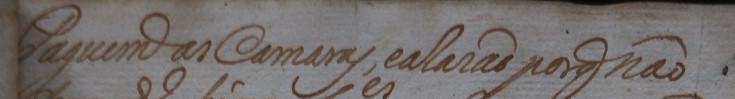

Origem,Texto
Referência diplomática,"Paguem as Camaras, e a Razão por não"
PP-OCRv5 mobile / ONNX,Cayuem n Camen ealia pognas.
PP-OCRv6 medium / Kraken 7.1,"Paquem as Camaras, e alazaõ porq̄ nao"


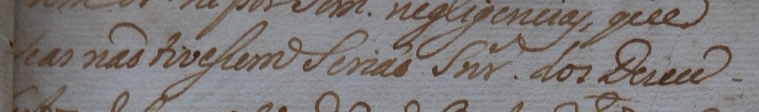

Origem,Texto
Referência diplomática,se as não tivessem seriam Srsˢ dos Desco-
PP-OCRv5 mobile / ONNX,n lmn r.do Ee
PP-OCRv6 medium / Kraken 7.1,cas nad tivessem Seriaõ Snr. dos Deseu


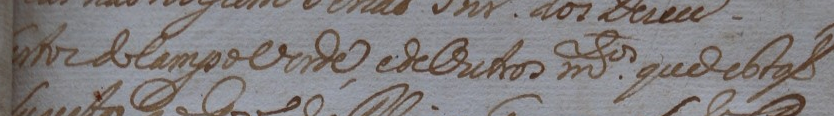

Origem,Texto
Referência diplomática,"bertos do campo verde, e de outros muⁱᵗᵒˢ que estão"
PP-OCRv5 mobile / ONNX,d
PP-OCRv6 medium / Kraken 7.1,"ntos do lampo vorde, e de Outros m.tos que estao"


In [4]:
# @title 4. Comparar cada manuscrito com as duas previsões
for indice, ref in enumerate(REFERENCIAS):
    linha = ref['reading_order'] + 1
    display(HTML(f'<h3>Linha {linha} do fólio 4r</h3>'))
    display(Image(data=base64.b64decode(RECORTES_BASE64[ref['line_id']]), format='png'))
    tabela(['Origem', 'Texto'], [('Referência diplomática', ref['text_diplomatic'])] + [
        (rotulo, PREDICOES[modelo][indice]['text_raw']) for modelo, rotulo in MODELOS.items()
    ])

## Principais erros da execução de 04/11

- **PP-OCRv5.** O padrão dominante foi a perda de conteúdo, com **86 deleções** de caracteres. Na linha 3, produziu `n lmn r.do Ee` para uma referência de oito palavras. Na linha 4, a saída foi apenas `d`. O alinhamento por palavras teve zero acertos exatos.
- **PP-OCRv6.** Retém mais conteúdo, com **8 deleções**, mas troca grafia, palavras e sinais. Na linha 1, `Paguem` virou `Paquem` e `por não` virou `porq̄ nao`. Na linha 3, `Srsˢ` virou `Snr.` e `Desco-` virou `Deseu`, sem o hífen final. Na linha 4, `campo verde` virou `lampo vorde`, `muⁱᵗᵒˢ` virou `m.tos` e `estão` virou `estao`.

O PP-OCRv6 teve CER e WER menores nas três linhas. Essa diferença é específica destas configurações e amostras. As variantes, os pesos, os runtimes e os pré-processamentos diferem. A avaliação por linha pressupõe recortes prontos e cobre três linhas do mesmo documento.

## Treino demonstrável e experimento com teste reservado

**Já executado em 23/10.** Ajuste fino técnico de **PP-OCRv6 medium** no Kraken, com duas linhas de treino e uma de validação técnica do mesmo documento de desenvolvimento. Os logs registram dois passos de otimização, atualização de pesos e uma inferência após a recarga do checkpoint. É a etapa que podemos demonstrar agora, com os logs ou com uma repetição local.

In [5]:
# @title 5. Consultar a evidência do ajuste fino técnico
EVIDENCIA = {'optimizer_steps': 2, 'changed_trainable_tensors': 318, 'reload_inference_ok': True, 'test_used': False, 'losses': [(1, 9.595231056213379), (2, 9.548118591308594)], 'reload_reference': 'torze Dias do mes de Dezembro da dita Hera nesta', 'reload_prediction': 'iorze dios do mej de Dezenbro da ditalera nesta'}
tabela(['Passo de otimização', 'Perda registrada'], [(passo, f'{perda:.6f}'.replace('.', ',')) for passo, perda in EVIDENCIA['losses']])
print(f"Tensores treináveis alterados: {EVIDENCIA['changed_trainable_tensors']}.")
print(f"Inferência após recarregar os pesos: {'confirmada' if EVIDENCIA['reload_inference_ok'] else 'pendente'}.")
tabela(['Verificação de recarga', 'Texto da linha de validação técnica'], [
    ('Referência', EVIDENCIA['reload_reference']),
    ('Previsão do checkpoint ajustado', EVIDENCIA['reload_prediction']),
])

Passo de otimização,Perda registrada
1,"9,595231"
2,"9,548119"


Tensores treináveis alterados: 318.
Inferência após recarregar os pesos: confirmada.


Verificação de recarga,Texto da linha de validação técnica
Referência,torze Dias do mes de Dezembro da dita Hera nesta
Previsão do checkpoint ajustado,iorze dios do mej de Dezenbro da ditalera nesta


As perdas são de dois exemplos diferentes. O ensaio comprova que o pipeline atualizou e recarregou pesos. A comparação CER/WER deste notebook usa os modelos pré-treinados, e o ganho do ajuste fino continua a ser medido em teste reservado.

**Demonstração opcional de treino local.** Na raiz do checkout, com os pesos e o Docker preparados, execute o ensaio técnico em uma pasta nova. Ele reutiliza somente os exemplos históricos de desenvolvimento registrados na configuração.

```powershell
.venv/Scripts/python.exe -m paleographia train --config configs/training_ppocrv6_smoke.toml --output-dir experiments/demo_professor_1767_01 --execute
```

**Quando treinar para medir ganho.** Nos dois pacotes revisados recentes há **10 pares** em dois documentos, 7 em 1795 e 3 nesta carta. A pré-verificação da configuração científica em 04/11 ainda exige independência documental confirmada. O próximo treino com avaliação começa quando houver dados suficientes de documentos independentes em **treino, validação e teste**, com a separação registrada antes da execução.

1. Validar mais referências e reservar documentos ainda fora do desenvolvimento. Manter páginas, cópias e derivados do mesmo documento no mesmo conjunto.
2. Ajustar o **PP-OCRv6** apenas no treino e escolher o checkpoint pela validação.
3. Rodar **PP-OCRv6 base e ajustado** nos mesmos recortes do teste reservado e comparar CER, WER e os erros. Fixar a política de normalização e as exclusões antes da inferência.

## Enquadramento acadêmico

- **PLN.** A orientação registrada pede um notebook de implementação comparando dois modelos. Esta continuação mostra entradas, previsões e métricas dos dois reconhecedores. A opção local permite demonstrar inferência nova.
- **PI IV.** O notebook documenta dados tratados e a comparação dos reconhecedores. A demonstração de ganho do ajuste fino fica para o experimento com teste reservado. O enquadramento de reconhecimento de texto manuscrito na etapa chamada **primeiro modelo de classificação** ainda precisa de confirmação docente. As orientações consultadas também indicam dataset público, declaração de IA e entrega final em Colab com artigo. As condições de uso das fontes seguem em conferência.

## Fontes, créditos e uso de IA

- Manuscrito de José Gomes de Gouveia, 1767, fólio 4r. Edição de Júlia Munhoz e Matheus Bellodi, com revisão de Isabella Ferraro, Arquivo Histórico Municipal de Jundiaí. A referência diplomática da avaliação foi validada por Rodolfo Vinicius Cima Takemoto. [Protocolo e execução](https://github.com/aj1no/paleographia-htr/blob/48ee44e8336f2d6338a9e6ddf7b419b48c9fa853/docs/entregas/continuidade_20261103/avaliacao_linhas_1767/README.md).
- Evidência do ajuste fino, incluindo configuração, logs e verificação da recarga. [Ensaio técnico](https://github.com/aj1no/paleographia-htr/blob/48ee44e8336f2d6338a9e6ddf7b419b48c9fa853/docs/dataset_expansion_20261023/README.md#ajuste-fino-realmente-executado).
- Orientações consultadas. *Apresentação do Projeto Integrador PI IV*, p. 10, 12–13 e 16–17. *05_The Transformer Revolution*, p. 45. *01_Processamento de Linguagem Natural*, p. 6. [Registro dos requisitos](https://github.com/aj1no/paleographia-htr/blob/48ee44e8336f2d6338a9e6ddf7b419b48c9fa853/docs/entregas/continuidade_20261103/README.md#requisitos-recuperados-dos-arquivos-originais).
- **Declaração de IA.** Codex (OpenAI) apoiou a organização do notebook, o código de recálculo, a conferência das saídas e a descrição dos erros. As previsões são dos dois reconhecedores identificados. A validação diplomática é humana.